<a href="https://colab.research.google.com/github/Nasim-Amani/solar/blob/main/1solar_data_SolarRad_clean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 120)

# ---- Load ----
df = pd.read_csv("cleaned_solar_data_Oct26.csv")
df["DateTime"] = pd.to_datetime(df["DateTime"], format="%Y-%m-%d %H:%M:%S")
df = df.sort_values("DateTime").set_index("DateTime")
s = df["Solar_Rad"]

# ---- 1) Timestamp checks ----
step = df.index.to_series().diff()
print(f"Period      : {df.index[0]}  ->  {df.index[-1]}")
print(f"Records     : {len(df):,}")
print(f"Duplicates  : {df.index.duplicated().sum():,}")
print(f"Gaps > 1 s  : {(step > pd.Timedelta('1s')).sum():,}  "
      f"(missing seconds: {int((step.dt.total_seconds() - 1).clip(lower=0).sum()):,})")

# ---- 2) Daily coverage: mark full days (>= 99.9% of 86,400 s) ----
coverage = df.groupby(df.index.date).size().rename("records").to_frame()
coverage["first"] = df.index.to_series().groupby(df.index.date).min().dt.time
coverage["last"]  = df.index.to_series().groupby(df.index.date).max().dt.time
coverage["full_day"] = coverage["records"] >= 0.999 * 86400
display(coverage)

full_days = coverage.index[coverage["full_day"]]
df["full_day"] = np.isin(df.index.date, full_days)
print(f"Full days: {full_days[0]} -> {full_days[-1]}  ({len(full_days)} days)")

# ---- 3) Solar_Rad basic summary ----
values = np.unique(s.values)
resolution = pd.Series(np.round(np.diff(values), 5)).mode()[0]
print(f"\nSolar_Rad: min {s.min():.3f} | median {s.median():.3f} | max {s.max():.3f} W/m²")
print(f"NaN {s.isna().sum():,} | <0 {(s < 0).sum():,} | ==0 {(s == 0).sum():,}")
print(f"Sensor/logger step (smallest change): {resolution} W/m²")

Period      : 2013-02-15 18:49:44  ->  2013-02-27 13:03:03
Records     : 1,015,991
Duplicates  : 0
Gaps > 1 s  : 9  (missing seconds: 9)


,records,first,last,full_day
2013-02-15,18615,18:49:44,23:59:59,False
2013-02-16,86398,00:00:00,23:59:59,True
2013-02-17,86399,00:00:00,23:59:59,True
2013-02-18,86395,00:00:00,23:59:59,True
2013-02-19,86400,00:00:00,23:59:59,True
2013-02-20,86400,00:00:00,23:59:59,True
2013-02-21,86400,00:00:00,23:59:59,True
2013-02-22,86400,00:00:00,23:59:59,True
2013-02-23,86400,00:00:00,23:59:59,True
2013-02-24,86400,00:00:00,23:59:59,True


Full days: 2013-02-16 -> 2013-02-26  (11 days)

Solar_Rad: min 1.978 | median 2.867 | max 1024.404 W/m²
NaN 0 | <0 0 | ==0 0
Sensor/logger step (smallest change): 0.03064 W/m²


In [2]:
# List the 9 gaps
step = df.index.to_series().diff()
gaps = step[step > pd.Timedelta("1s")]
display(pd.DataFrame({"gap_ends_at": gaps.index, "gap_length": gaps.values}))

,gap_ends_at,gap_length
0,2013-02-15 18:49:48,0 days 00:00:02
1,2013-02-16 05:38:40,0 days 00:00:02
2,2013-02-16 22:52:56,0 days 00:00:02
3,2013-02-17 02:30:36,0 days 00:00:02
4,2013-02-18 05:47:48,0 days 00:00:02
5,2013-02-18 16:29:56,0 days 00:00:02
6,2013-02-18 19:33:56,0 days 00:00:02
7,2013-02-18 20:30:21,0 days 00:00:02
8,2013-02-18 22:47:57,0 days 00:00:02


## 1. Data Loading and Timestamp Quality Check

### What we did
- Checked the timestamps for **duplicates** and **gaps** (any step longer than 1 s).
- Counted the records per day to find **complete days** (≥ 99.9% of 86,400 s) and added a `full_day` flag.
- Summarised `Solar_Rad`: range, missing, zero and negative values, and the sensor's smallest step (resolution).

### Results

| Check | Result |
|---|---|
| Period | 2013-02-15 18:49:44 → 2013-02-27 13:03:03 |
| Records | 1,015,991 at 1-s resolution |
| Duplicate timestamps | 0 |
| Missing records | 9 isolated seconds (< 0.001%) |
| Complete days | 11 (Feb 16 – Feb 26) |
| Partial days | Feb 15 (from 18:49) and Feb 27 (until 13:03) |
| `Solar_Rad` range | 1.98 – 1,024.40 W/m² |
| Missing / zero / negative values | 0 / 0 / 0 |
| Sensor resolution | 0.03064 W/m² |

### Interpretation
- **The time axis is reliable.** It has no duplicates, and the only gaps are 9 single missing seconds. Each one is a 2-s step, typical of a skipped logger write. Eight of them fall at night or twilight and one in the late afternoon (Feb 18, 16:29), so filling them by interpolation has no meaningful effect.
- **Only complete days should be used for daily statistics.** The partial first and last days would bias daily totals and means, so later analysis uses the `full_day` flag.
- **Night readings are not zero.** No value is zero or negative, and the median (2.87 W/m²) lies at the night level. This shows a small, constant **positive sensor offset** (~2.7 W/m²) that is present all the time. It is removed in a later step instead of simply setting night values to zero.
- **The sensor is precise.** Values change in fixed steps of 0.03064 W/m², which is the logger's resolution. Night variability is only a few steps, so the offset can be estimated accurately.
- **The daytime maximum (1,024 W/m²) is physically plausible.** There is no sign of over-range values.

#Visual check of the daily cycle

Before cleaning anything, we look at the data for the 11 complete days. This cell answers three questions:

1. Does every day have a normal shape: night, then a rise, a peak and a fall?
2. Is the night level flat and the same every night? *That is needed before we remove the offset.*
3. Are there odd daytime events, such as sudden drops, spikes or flat sections?

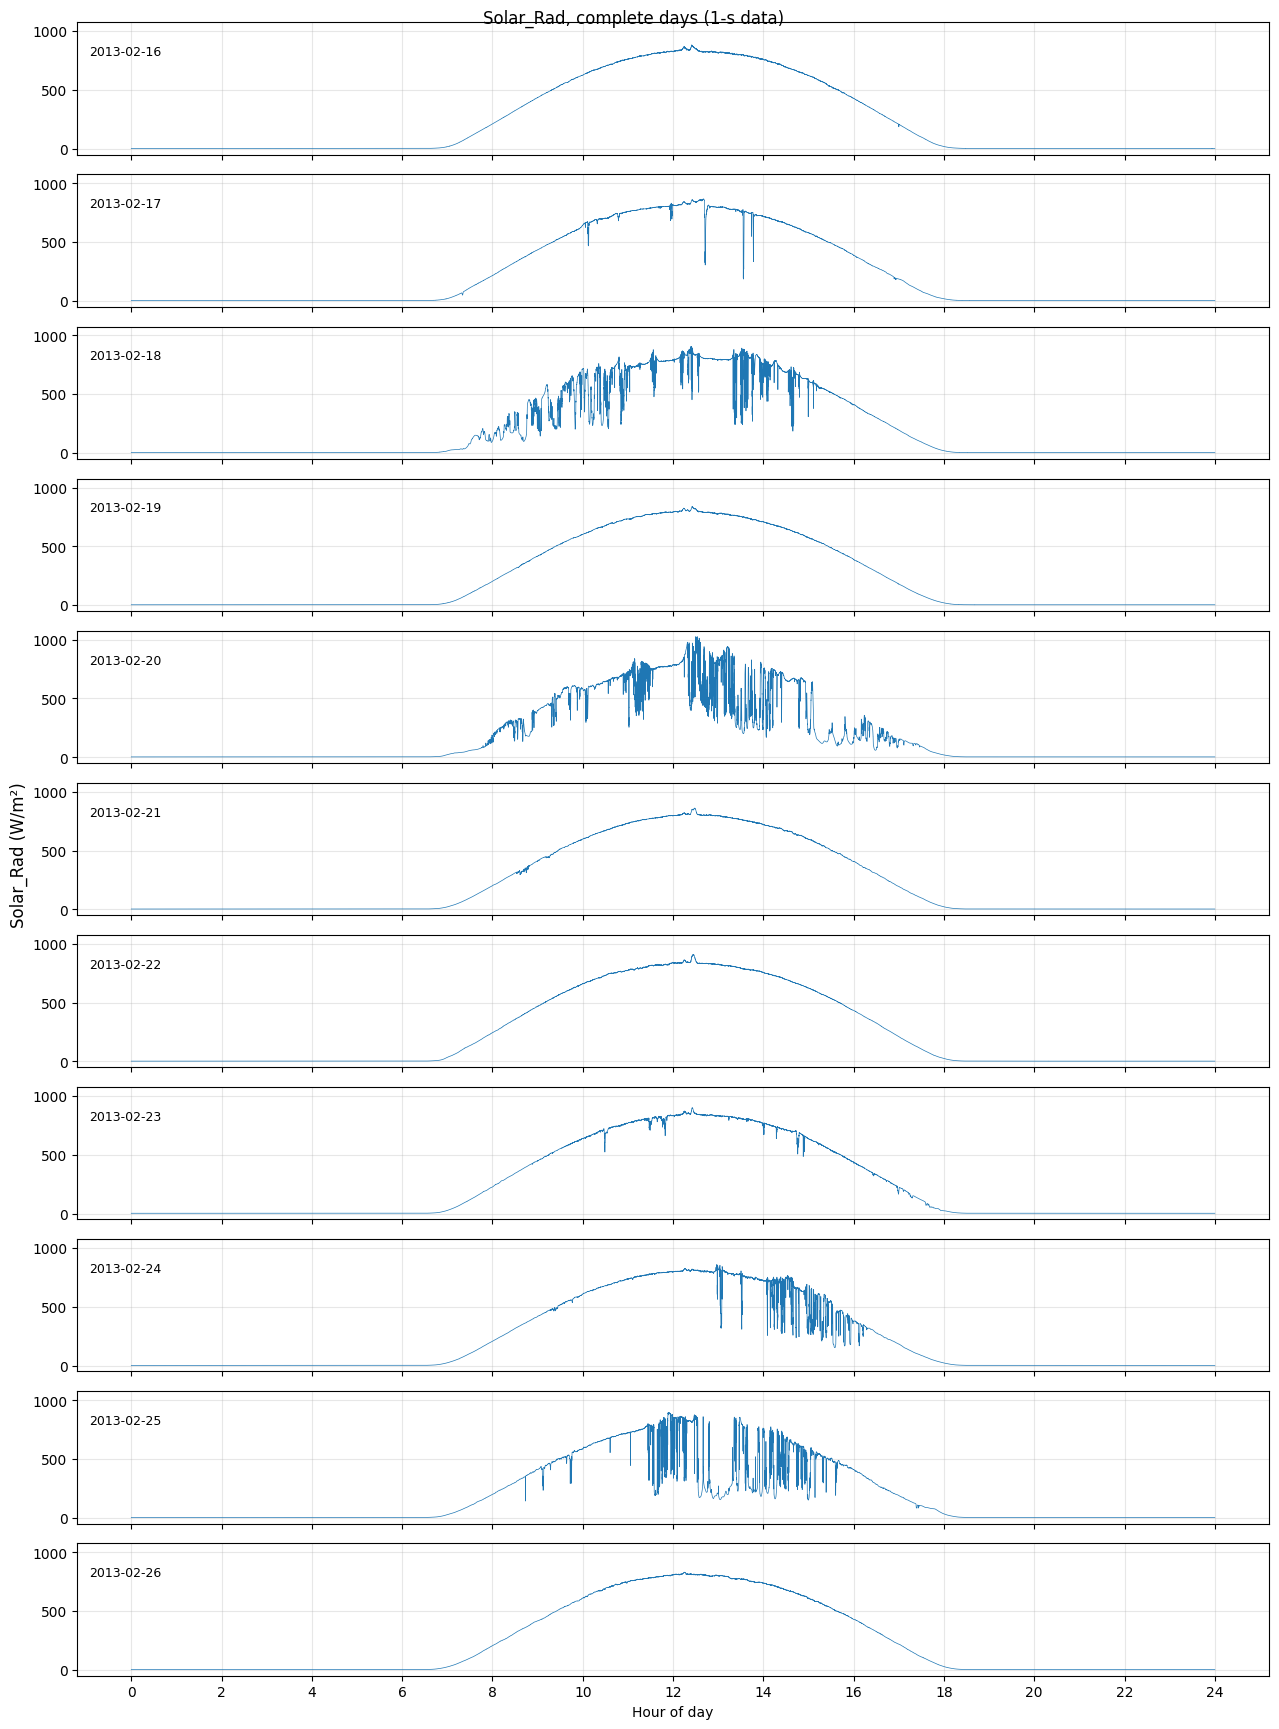

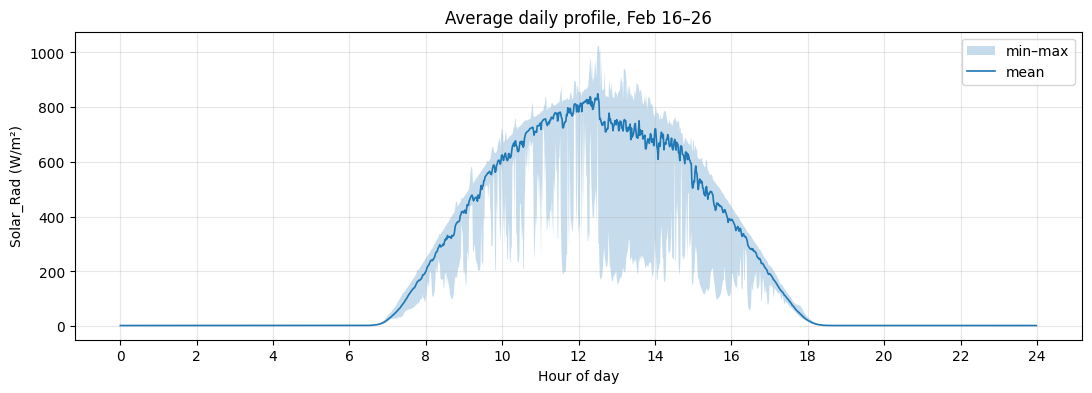

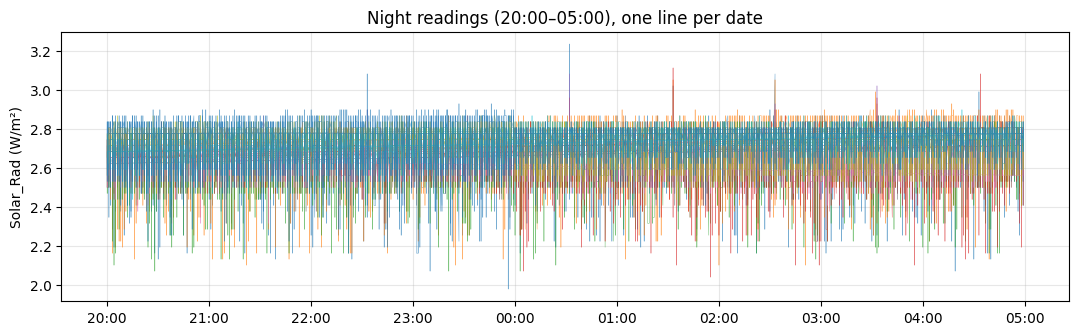

count    356396.000
mean          2.717
std           0.064
min           1.978
25%           2.683
50%           2.713
75%           2.744
max           3.234
Name: Solar_Rad, dtype: float64


In [3]:
full = df.loc[df["full_day"], "Solar_Rad"]
hour = full.index.hour + full.index.minute / 60 + full.index.second / 3600

# ---- A) One panel per complete day ----
days = sorted(set(full.index.date))
fig, axes = plt.subplots(len(days), 1, figsize=(13, 1.6 * len(days)), sharex=True, sharey=True)
for ax, day in zip(axes, days):
    d = full[full.index.date == day]
    ax.plot(hour[full.index.date == day], d, lw=0.5)
    ax.text(0.01, 0.75, str(day), transform=ax.transAxes, fontsize=9)
    ax.grid(alpha=0.3)
axes[-1].set_xticks(range(0, 25, 2))
axes[-1].set_xlabel("Hour of day")
fig.supylabel("Solar_Rad (W/m²)")
fig.suptitle("Solar_Rad, complete days (1-s data)")
plt.tight_layout()
plt.show()

# ---- B) Average daily profile (1-min bins) ----
minute = (full.index.hour * 60 + full.index.minute)
profile = full.groupby(minute).agg(["mean", "min", "max"])
fig, ax = plt.subplots(figsize=(13, 4))
ax.fill_between(profile.index / 60, profile["min"], profile["max"], alpha=0.25, label="min–max")
ax.plot(profile.index / 60, profile["mean"], lw=1.2, label="mean")
ax.set_xticks(range(0, 25, 2))
ax.set_xlabel("Hour of day")
ax.set_ylabel("Solar_Rad (W/m²)")
ax.set_title("Average daily profile, Feb 16–26")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# ---- C) Night level: zoom on 20:00–05:00 ----
night = full[(full.index.hour >= 20) | (full.index.hour < 5)]
night_hour = (night.index.hour + night.index.minute / 60 + 4) % 24   # 20:00 -> 0, 05:00 -> 9
fig, ax = plt.subplots(figsize=(13, 3.5))
for day in days:
    m = night.index.date == day
    ax.plot(night_hour[m], night[m], lw=0.4, alpha=0.6)
ax.set_xticks(range(0, 10), [f"{(h + 20) % 24:02d}:00" for h in range(0, 10)])
ax.set_ylabel("Solar_Rad (W/m²)")
ax.set_title("Night readings (20:00–05:00), one line per date")
ax.grid(alpha=0.3)
plt.show()

print(night.describe().round(3))

In [4]:
spike_min = night.groupby(night.index.minute).max()
print(spike_min.sort_values(ascending=False).head(5).round(3))

DateTime
32    3.234
33    3.112
34    3.081
27    2.928
46    2.928
Name: Solar_Rad, dtype: float64


## 2. Visual Inspection of the Daily Cycle (complete days, Feb 16–26)

### What we did
- Plotted `Solar_Rad` at full 1-s resolution, one panel per complete day.
- Built the average daily profile (1-min bins) with its min–max range.
- Zoomed in on the night period (20:00–05:00) to examine the sensor's night level.
- Found the minute of the hour with the highest night readings, to test for a periodic artifact.

### Results and interpretation

**A. Daily patterns**
- **Clear days:** Feb 16, 19, 21, 22, 26 (and mostly 23). These show a smooth, bell-shaped curve peaking at about 800–850 W/m².
- **Cloudy or partly cloudy days:** Feb 18, 20, 24 (afternoon) and 25, with short dips on Feb 17. The sharp, short drops are passing clouds, which 1-s data captures in full detail. They are **real**, not errors.
- **Maximum of 1,024 W/m² (Feb 20, ~12:30):** a **cloud-enhancement** event. Light reflected from cloud edges briefly adds to direct sunlight, pushing values above the clear-sky curve. It is physically valid and is **kept**.
- **Repeated small features:** a small bump (~+30–80 W/m²) around 12:20–12:40 on most clear days, and possible small notches near 17:00. Because they occur at the same time on different days, they are likely caused by the site (reflection or partial shading), not by the weather. They are noted but not corrected.

**B. Average profile**
- Light begins at about **06:45** and ends at about **18:15**, so the midpoint of the day is about **12:30 (clock time)**.
- The profile is less smooth in the afternoon because more clouds occurred after noon during this period.
- The upper envelope (max line) is smooth and symmetric, which supports consistent timestamps.

**C. Night readings (20:00–05:00)**

| Statistic | Value (W/m²) |
|---|---|
| Records | 356,396 |
| Mean | 2.717 |
| Median | 2.713 |
| Std | 0.064 |
| Min / Max | 1.978 / 3.234 |

- The night level is **flat and stable**: there is no trend through the night and no step at midnight. This is a **constant sensor offset of about 2.71 W/m²**, not real radiation.
- Variability is very low (std ≈ 2 sensor steps of 0.03064 W/m²).
- Short downward excursions (to ~2.0 W/m²) are random noise.

**D. Hourly night spikes**

| Minute of the hour | Max night value (W/m²) |
|---|---|
| 32 | 3.234 |
| 33 | 3.112 |
| 34 | 3.081 |
| 27 | 2.928 |
| 46 | 2.928 |

- The three highest night values fall at **minutes 32–34**, confirming a small **hourly spike at about hh:33**.
- Its regular timing points to an **electrical or logging artifact**, not to light.
- The amplitude is only +0.3 to +0.5 W/m² (< 0.05% of the daytime peak), so it is negligible for the analysis.

### Conclusions for cleaning
1. Remove a **constant offset of ≈ 2.71 W/m²** (the night median) from the whole series, then set the remaining small negative values to 0.
2. **Keep** cloud dips and cloud-enhancement peaks. They are real atmospheric signals.
3. Cloudy days are **valid data**, not bad data. They show the natural variability of solar radiation.
4. The midday bump, the late-afternoon notches and the hourly spike are minor site or logger features. They are **documented but not corrected**.

#Removal of the Sensor Offset → `Solar_Rad_clean`

Sensor offset (night median): 2.7134 W/m²
Values set to 0 after subtraction: 166,654 (16.4%)


,Night raw,Night clean,05–20 h raw,05–20 h clean
count,388796.000,388796.000,627195.000,627195.000
mean,2.721,0.028,359.814,357.105
std,0.068,0.038,311.982,311.977
min,1.978,0.000,2.101,0.000
25%,2.683,0.000,10.649,7.936
50%,2.713,0.000,318.367,315.653
75%,2.775,0.061,679.061,676.347
max,3.234,0.521,1024.404,1021.691


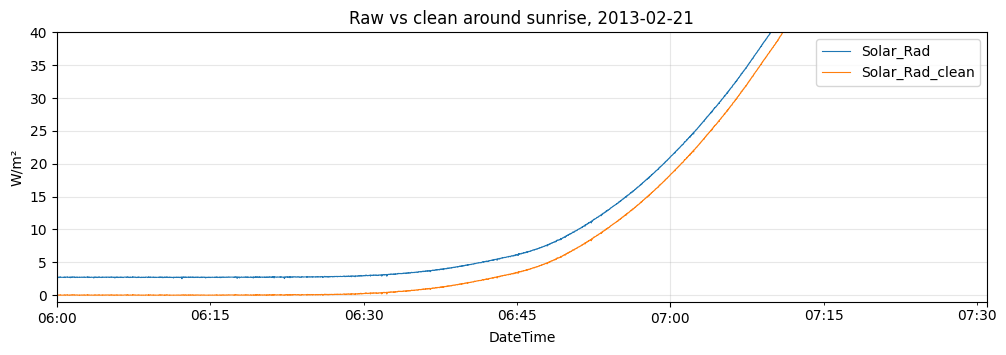

In [5]:
# ---- 1) Offset = median of night readings (20:00–05:00) on complete days ----
is_night = (df.index.hour >= 20) | (df.index.hour < 5)
OFFSET = df.loc[is_night & df["full_day"], "Solar_Rad"].median()
print(f"Sensor offset (night median): {OFFSET:.4f} W/m²")

# ---- 2) New clean column (original Solar_Rad is NOT changed) ----
df["Solar_Rad_clean"] = (df["Solar_Rad"] - OFFSET).clip(lower=0)

# ---- 3) Checks ----
n_clipped = int((df["Solar_Rad"] - OFFSET < 0).sum())
print(f"Values set to 0 after subtraction: {n_clipped:,} ({n_clipped / len(df):.1%})")

summary = pd.DataFrame({
    "Night raw":         df.loc[is_night,  "Solar_Rad"].describe(),
    "Night clean":       df.loc[is_night,  "Solar_Rad_clean"].describe(),
    "05–20 h raw":       df.loc[~is_night, "Solar_Rad"].describe(),
    "05–20 h clean":     df.loc[~is_night, "Solar_Rad_clean"].describe(),
}).round(3)
display(summary)

# ---- 4) Plot: raw vs clean around sunrise on one clear day ----
day = "2013-02-21"
w = df.loc[f"{day} 06:00":f"{day} 07:30", ["Solar_Rad", "Solar_Rad_clean"]]
ax = w.plot(figsize=(12, 3.5), lw=0.8, title=f"Raw vs clean around sunrise, {day}")
ax.set_ylim(-1, 40)
ax.set_ylabel("W/m²")
ax.grid(alpha=0.3)
plt.show()

## 3. Removal of the Sensor Offset → `Solar_Rad_clean`

### What we did
The correction was done in three steps:

1. **Estimate the offset:** the **median of all night readings (20:00–05:00) on complete days** = **2.7134 W/m²**.
2. **Subtract the offset from every record (day and night):** `Solar_Rad − 2.7134`
   - Night values **above** the median → small positive values
   - Night values **equal to** the median → exactly 0
   - Night values **below** the median → small negative values (sensor noise)
   - Daytime values → reduced by 2.71 W/m²
3. **Set negative values to 0**, since radiation cannot be negative.

The result is stored in a **new column, `Solar_Rad_clean`**. The original `Solar_Rad` is kept unchanged for comparison and traceability.

**Correction applied:** `Solar_Rad_clean = max(Solar_Rad − 2.7134, 0)`

**Example:**

| Raw | After subtraction | Clean |
|---|---|---|
| 2.652 | −0.061 | **0** |
| 2.713 | 0.000 | **0** |
| 2.775 | 0.061 | 0.061 |
| 800.000 | 797.287 | 797.287 |

**Why subtract from daytime values too?** The offset is part of every sensor reading, not only at night. Setting only the night values to 0 would leave daytime values 2.71 W/m² too high and create a small artificial jump at sunrise and sunset.

### Results

| Statistic (W/m²) | Night raw | Night clean | 05–20 h raw | 05–20 h clean |
|---|---|---|---|---|
| Count | 388,796 | 388,796 | 627,195 | 627,195 |
| Mean | 2.721 | 0.028 | 359.814 | 357.105 |
| Median | 2.713 | 0.000 | 318.367 | 315.653 |
| Std | 0.068 | 0.038 | 311.982 | 311.977 |
| Min | 1.978 | 0.000 | 2.101 | 0.000 |
| Max | 3.234 | 0.521 | 1,024.404 | 1,021.691 |

- **Offset:** 2.7134 W/m², which is one of the sensor's discrete reading levels (step size 0.03064 W/m²).
- **Negative values set to 0:** 166,654 (16.4% of all records). These are night-level readings (mostly night, plus a few at dawn and dusk) below the median. Readings exactly equal to the median also become 0, so the total share of zeros is higher than 16.4%.

### Interpretation
- **Night values are now ≈ 0**: the median is 0, the mean is 0.028 W/m², and the maximum is 0.52 W/m² (the small hourly spike). The clean column now behaves as expected physically.
- **Daytime values are shifted down by a constant 2.71 W/m² and their shape is unchanged.** The standard deviation is the same before and after (311.98), which confirms the correction moves the curve without distorting it.
- **The effect on daytime data is very small**: 2.71 W/m² is under 0.3% of the daily peak, but it matters at low sun angles (early morning and late afternoon).
- **The sunrise plot (Feb 21)** shows the clean curve starting at 0 and rising smoothly from about **06:25**. There is no step or artificial jump, so the correction does not introduce artifacts.
- **The cloud-enhancement peak is kept** (1,021.7 W/m² after correction).

#Daylight Start, End and Midpoint → `daylight` flag

/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  cast_date_col = pd.to_datetime(column, errors="coerce")
/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  cast_date_col = pd.to_datetime(column, errors="coerce")
/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  cast_date_col = pd.to_datetime(column, errors="coerce")


,Start,End,Length_h,Midpoint
Date,,,,
2013-02-15,NaN,NaN,NaN,NaN
2013-02-16,06:38:25,18:23:21,11.75,12:30:53
2013-02-17,06:37:56,18:21:18,11.72,12:29:37
2013-02-18,06:40:07,18:22:39,11.71,12:31:23
2013-02-19,06:37:30,18:23:12,11.76,12:30:21
2013-02-20,06:38:16,18:23:11,11.75,12:30:43
2013-02-21,06:36:31,18:25:13,11.81,12:30:52
2013-02-22,06:34:14,18:25:43,11.86,12:29:58
2013-02-23,06:34:33,18:26:37,11.87,12:30:35


Start    : 06:38 → 06:32  (first → last complete day)
End      : 18:23 → 18:27  (first → last complete day)
Midpoint : 12:31 → 12:30  (first → last complete day)
Day length: 11.81 h on average

Daylight records: 491,410 (48.4%)


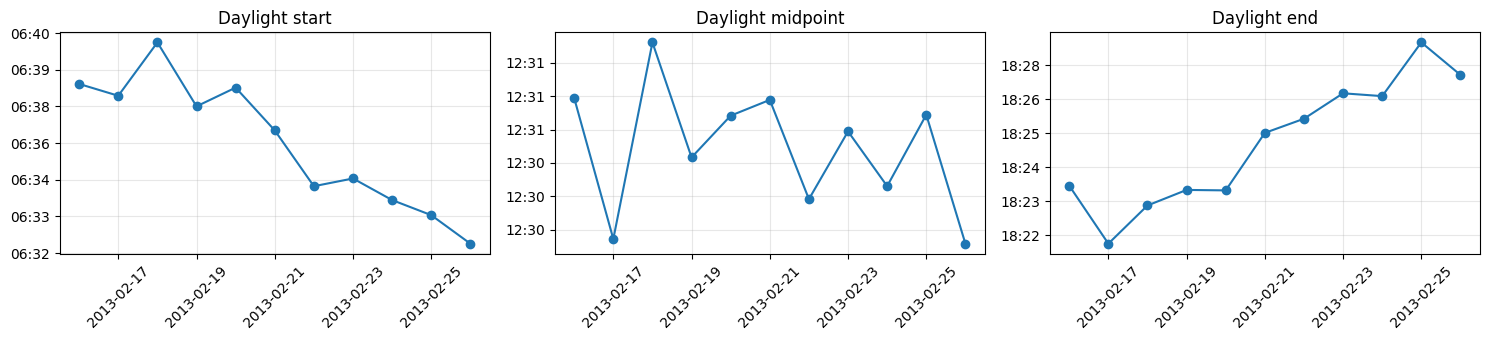

In [7]:
# ---- Settings ----
THRESHOLD = 1.0        # W/m², above the night noise (night clean max = 0.52)
SMOOTH    = "1min"     # rolling median removes 1-s noise and the hourly spikes
SUSTAIN   = pd.Timedelta(minutes=10)   # light must stay above threshold this long

# ---- 1) Smooth and find sustained "light" periods ----
smooth = df["Solar_Rad_clean"].rolling(SMOOTH, center=True).median()
above = smooth > THRESHOLD
run_id = above.ne(above.shift()).cumsum()
runs = (df.index.to_series()[above]
          .groupby(run_id[above]).agg(["first", "last"]))
runs = runs[runs["last"] - runs["first"] >= SUSTAIN]

# ---- 2) Daylight start / end per day ----
day_last = df.index.to_series().groupby(df.index.date).max()
rows = []
for date in day_last.index:
    r = runs[runs["first"].dt.date == date]
    start = r["first"].min() if len(r) else pd.NaT
    end   = r["last"].max()  if len(r) else pd.NaT
    # end is unknown if light continues until the data stops (Feb 27)
    if pd.notna(end) and end >= day_last[date] - pd.Timedelta(seconds=30):
        end = pd.NaT
    rows.append({"Date": date, "Start": start, "End": end})

daylight = pd.DataFrame(rows).set_index("Date")
daylight["Length_h"] = (daylight["End"] - daylight["Start"]).dt.total_seconds() / 3600
daylight["Midpoint"] = daylight["Start"] + (daylight["End"] - daylight["Start"]) / 2

show = daylight.copy()
for c in ["Start", "End", "Midpoint"]:
    show[c] = show[c].dt.strftime("%H:%M:%S")
display(show.round(2))

full = daylight.loc[coverage.index[coverage["full_day"]]]
to_h = lambda t: (t - t.dt.normalize()).dt.total_seconds() / 3600
hhmm = lambda h: "{:02d}:{:02d}".format(*divmod(int(round(h * 60)), 60))
for col in ["Start", "End", "Midpoint"]:
    h = to_h(full[col])
    print(f"{col:9}: {hhmm(h.iloc[0])} → {hhmm(h.iloc[-1])}  (first → last complete day)")
print(f"Day length: {full['Length_h'].mean():.2f} h on average")

# ---- 3) Daylight flag column ----
df["daylight"] = False
for date, row in daylight.iterrows():
    end = row["End"] if pd.notna(row["End"]) else day_last[date]
    if pd.notna(row["Start"]):
        df.loc[row["Start"]:end, "daylight"] = True
print(f"\nDaylight records: {df['daylight'].sum():,} ({df['daylight'].mean():.1%})")

# ---- 4) Plot start, midpoint and end per complete day ----
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, col in zip(ax, ["Start", "Midpoint", "End"]):
    a.plot(pd.to_datetime(full.index), to_h(full[col]), marker="o")
    a.yaxis.set_major_formatter(lambda y, _: hhmm(y))
    a.set_title(f"Daylight {col.lower()}")
    a.grid(alpha=0.3)
    a.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## 4. Daylight Start, End and Midpoint → `daylight` flag

### What we did
- Smoothed `Solar_Rad_clean` with a **1-min rolling median** to remove 1-s noise and the small hourly spikes.
- Defined "light" as **> 1 W/m²**, about twice the highest clean night value (0.52 W/m²).
- Required light to last **at least 10 minutes**, so short spikes cannot be mistaken for sunrise.
- For each day: **start** = first sustained light, **end** = last sustained light, **midpoint** = halfway between them, **length** = end − start.
- Added a new **`daylight` column** (True between start and end) for later steps.
- Partial days: Feb 15 starts after sunset, so it has no daylight. On Feb 27 the data stops at 13:03, so its end is left empty.

### Results (complete days, Feb 16–26)

| Date | Start | End | Length (h) | Midpoint |
|---|---|---|---|---|
| 02-16 | 06:38:25 | 18:23:21 | 11.75 | 12:30:53 |
| 02-17 | 06:37:56 | 18:21:18 | 11.72 | 12:29:37 |
| 02-18 | 06:40:07 | 18:22:39 | 11.71 | 12:31:23 |
| 02-19 | 06:37:30 | 18:23:12 | 11.76 | 12:30:21 |
| 02-20 | 06:38:16 | 18:23:11 | 11.75 | 12:30:43 |
| 02-21 | 06:36:31 | 18:25:13 | 11.81 | 12:30:52 |
| 02-22 | 06:34:14 | 18:25:43 | 11.86 | 12:29:58 |
| 02-23 | 06:34:33 | 18:26:37 | 11.87 | 12:30:35 |
| 02-24 | 06:33:40 | 18:26:31 | 11.88 | 12:30:05 |
| 02-25 | 06:33:03 | 18:28:25 | 11.92 | 12:30:44 |
| 02-26 | 06:31:53 | 18:27:16 | 11.92 | 12:29:34 |

- **Average day length:** 11.81 h
- **Daylight records:** 491,410 (48.4% of the dataset)

### Interpretation
- **The clock is stable.** The midpoint stays at **12:30 ± 1 min** on all 11 days, with no drift, jumps or daylight-saving change. This confirms the timestamps are internally consistent.
- **Days get longer.** Start moves ~6 min earlier and end ~4 min later, so day length rises from 11.75 to 11.92 h (~1 min/day). This is consistent with a **northern-hemisphere site in late winter**.
- **The method is robust.** Cloudy days (Feb 18, 20, 24, 25) give start and end times in line with clear days, because clouds never reduce the radiation below 1 W/m².
- **Interpretation of the times:** these are times of *measurable light* (> 1 W/m²). They are close to, but not identical with, astronomical sunrise and sunset, since twilight can exceed the threshold for a few minutes.
- **Time-zone check:** if the logger used local standard time, a midpoint of 12:30 implies the site is ~4° west of its time zone's central meridian. This should be compared with the known station location.

In [9]:
df

,Amb_Tempr,Solar_Rad,Tempr_PV_1,Tempr_PV_2,Tempr_PV_3,PV_1_SA_V,PV_4_Hor_V,PV_1_SA_I,PV_2_GT_I,PV_3_Tr_I,PV_4_Hor_I,full_day,Solar_Rad_clean,daylight
DateTime,,,,,,,,,,,,,,
2013-02-15 18:49:44,20.922115,2.437606,13.257263,12.494228,13.441733,0.000000,-0.617625,-0.013561,-0.009259,0.000398,-0.086931,False,0.000000,False
2013-02-15 18:49:45,20.897755,2.468246,13.254468,12.499819,13.450118,0.000000,-0.617625,-0.013561,-0.008453,0.001171,-0.084999,False,0.000000,False
2013-02-15 18:49:46,20.897755,2.468246,13.254468,12.499819,13.450118,0.000000,-0.617625,-0.013561,-0.008453,0.001171,-0.084999,False,0.000000,False
2013-02-15 18:49:48,20.922115,2.560166,13.254468,12.505408,13.458504,0.000000,-0.617625,-0.013561,-0.007647,0.001944,-0.083453,False,0.000000,False
2013-02-15 18:49:49,20.934296,2.652086,13.262854,12.505408,13.458504,0.000000,-0.617625,-0.011653,-0.007244,0.003103,-0.083839,False,0.000000,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2013-02-27 13:02:59,24.137634,828.216248,49.941639,47.068378,46.956581,40.115028,19.692236,-0.093667,7.793015,0.123663,0.098546,False,825.502882,True
2013-02-27 13:03:00,24.129515,827.940491,49.938847,47.059994,46.937016,40.117416,19.465393,-0.093667,7.815180,0.122504,0.086954,False,825.227125,True
2013-02-27 13:03:01,24.129515,829.533752,49.944435,47.062790,46.906269,40.119804,19.380699,-0.093667,7.805911,0.121731,0.206741,False,826.820387,True


In [10]:
OUT = "solar_data_SolarRad_clean.csv"
df.to_csv(OUT, float_format="%.6f")          # DateTime index is saved as the first column
print(f"Saved {len(df):,} rows × {df.shape[1]} columns -> {OUT}")


Saved 1,015,991 rows × 14 columns -> solar_data_SolarRad_clean.csv
